# 04. Đánh giá, tinh chỉnh và phân tích lỗi

**Mục tiêu học:** đánh giá mô hình một cách trung thực; tinh chỉnh siêu tham số đúng cách (không "nhìn trộm" tập test); hiểu mô hình sai ở đâu; đưa ra **khoảng dự đoán** thay vì một con số.

**Nội dung**
1. Vì sao độ đo quan trọng: xếp hạng mô hình thay đổi theo độ đo
2. Tinh chỉnh siêu tham số bằng `RandomizedSearchCV`
3. Đánh giá cuối cùng trên tập test (chỉ một lần)
4. Phân tích lỗi: sai ở đâu?
5. Đường cong học: cần thêm dữ liệu hay mô hình tốt hơn?
6. Khoảng dự đoán bằng quantile regression
7. Lưu mô hình và những cạm bẫy thường gặp

In [1]:
import sys, warnings
from pathlib import Path
warnings.filterwarnings("ignore")
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, cross_val_score

from used_car_price.config import FEATURES, CATEGORICAL, NUMERIC, TARGET, RANDOM_STATE, RAW_PATH, TEST_SIZE
from used_car_price.data import load_data
from used_car_price.features import build_preprocessor
from used_car_price.train import log_target, candidates
from used_car_price.metrics import evaluate

pd.set_option("display.max_columns", 30); pd.set_option("display.width", 140)
plt.rcParams["figure.figsize"] = (7, 4.2)

df = load_data(); X, y = df[FEATURES], df[TARGET]
X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=TEST_SIZE, random_state=RANDOM_STATE)

from sklearn.model_selection import RandomizedSearchCV, cross_validate, learning_curve, KFold
from sklearn.pipeline import Pipeline
from sklearn.ensemble import GradientBoostingRegressor, RandomForestRegressor
from scipy.stats import randint, uniform
import joblib

## 1. Vì sao độ đo quan trọng

Ta chấm 4 mô hình ứng viên bằng **nhiều độ đo cùng lúc** (cross-validation 5 lần trên tập train).

In [2]:
scoring = {"MAPE": "neg_mean_absolute_percentage_error", "MAE": "neg_mean_absolute_error", "RMSE": "neg_root_mean_squared_error", "R2": "r2"}
rows = {}
for name, pipe in candidates().items():
    cv = cross_validate(pipe, X_tr, y_tr, cv=5, scoring=scoring, n_jobs=-1)
    rows[name] = {k: (-cv[f"test_{k}"].mean() if k != "R2" else cv[f"test_{k}"].mean()) for k in scoring}
res = pd.DataFrame(rows).T
display(res.round(3))
print("Xếp hạng (1 = tốt nhất) theo từng độ đo:")
rank = pd.DataFrame({"MAPE": res["MAPE"].rank(), "MAE": res["MAE"].rank(), "RMSE": res["RMSE"].rank(), "R2": (-res["R2"]).rank()}).astype(int)
display(rank)

,MAPE,MAE,RMSE,R2
linear_regression (baseline),0.173,198.027,454.657,0.828
ridge,0.175,203.301,463.870,0.821
random_forest,0.137,148.462,390.340,0.872
gradient_boosting,0.137,147.261,376.525,0.879


Xếp hạng (1 = tốt nhất) theo từng độ đo:


,MAPE,MAE,RMSE,R2
linear_regression (baseline),3,3,3,3
ridge,4,4,4,4
random_forest,1,2,2,2
gradient_boosting,2,1,1,1


**Quan sát:** xếp hạng có thể **không giống nhau** giữa các độ đo. RMSE/MAE tính theo triệu đồng bị các xe vài tỉ chi phối; MAPE coi mọi xe như nhau theo tỉ lệ %. Phải chọn độ đo trước, dựa trên câu hỏi: *người dùng muốn gì?* Ở đây ta chọn **MAPE** (và sai số % trung vị để tránh bị vài điểm tệ kéo).

## 2. Tinh chỉnh siêu tham số bằng RandomizedSearchCV

Quy tắc vàng: **chỉ dùng tập train** (với cross-validation bên trong) để chọn tham số. Tập test để dành đến cuối.

In [3]:
from used_car_price.features import build_preprocessor
gb_pipe = log_target(Pipeline([("prep", build_preprocessor(False)), ("model", GradientBoostingRegressor(random_state=0))]))
space = {"regressor__model__n_estimators": randint(300, 1200),
         "regressor__model__learning_rate": uniform(0.02, 0.1),
         "regressor__model__max_depth": randint(3, 7),
         "regressor__model__subsample": uniform(0.6, 0.4),
         "regressor__model__min_samples_leaf": randint(1, 10)}
search = RandomizedSearchCV(gb_pipe, space, n_iter=12, cv=3, scoring="neg_mean_absolute_percentage_error",
                            random_state=0, n_jobs=-1, verbose=0).fit(X_tr, y_tr)
print(f"MAPE CV tốt nhất: {-search.best_score_:.2%}")
print({k.replace("regressor__model__", ""): (round(v, 3) if isinstance(v, float) else v) for k, v in search.best_params_.items()})

r = pd.DataFrame(search.cv_results_)
r["MAPE"] = -r["mean_test_score"]
display(r[["MAPE"] + [c for c in r.columns if c.startswith("param_")]].sort_values("MAPE").head(6).round(3).rename(columns=lambda c: c.replace("param_regressor__model__", "")))

MAPE CV tốt nhất: 13.38%
{'learning_rate': np.float64(0.034), 'max_depth': 6, 'min_samples_leaf': 1, 'n_estimators': 843, 'subsample': np.float64(0.642)}


,MAPE,learning_rate,max_depth,min_samples_leaf,n_estimators,subsample
7,0.134,0.034,6,1,843,0.642
4,0.141,0.029,6,1,1055,0.983
0,0.143,0.075,4,1,1135,0.943
6,0.144,0.066,6,4,723,0.856
2,0.145,0.109,3,2,786,0.925
8,0.146,0.067,5,3,483,0.687


**Bài học:** tìm kiếm ngẫu nhiên thường hiệu quả hơn lưới đều khi có nhiều tham số. Hãy xem **độ lệch** giữa các cấu hình tốt nhất: nếu chênh nhau rất ít, việc tinh chỉnh thêm không đáng; quan trọng hơn là chất lượng dữ liệu và đặc trưng.

## 3. Đánh giá cuối cùng trên tập test (chỉ một lần)

In [4]:
best = search.best_estimator_
pred = best.predict(X_te)
final = evaluate(y_te, pred)
print({k: round(v, 3) for k, v in final.items()})

baseline = evaluate(y_te, np.full(len(y_te), y_tr.median()))
lin = candidates()["linear_regression (baseline)"].fit(X_tr, y_tr)
display(pd.DataFrame({"đoán trung vị": baseline, "tuyến tính (log)": evaluate(y_te, lin.predict(X_te)), "GB đã tinh chỉnh": final}).T.round(3))

{'MAPE': 0.108, 'sai_so_%_trung_vi': 0.07, 'MAE': 117.919, 'RMSE': 265.776, 'R2': 0.954}


,MAPE,sai_so_%_trung_vi,MAE,RMSE,R2
đoán trung vị,0.652,0.527,696.577,1304.988,-0.102
tuyến tính (log),0.158,0.094,190.264,440.092,0.875
GB đã tinh chỉnh,0.108,0.070,117.919,265.776,0.954


Mô hình tinh chỉnh phải thắng cả baseline ngớ ngẩn lẫn baseline tuyến tính. Nếu chỉ hơn một chút, hãy tự hỏi: chênh lệch có ý nghĩa thống kê không? (Xem độ lệch chuẩn qua các fold ở trên.)

## 4. Phân tích lỗi: sai ở đâu?

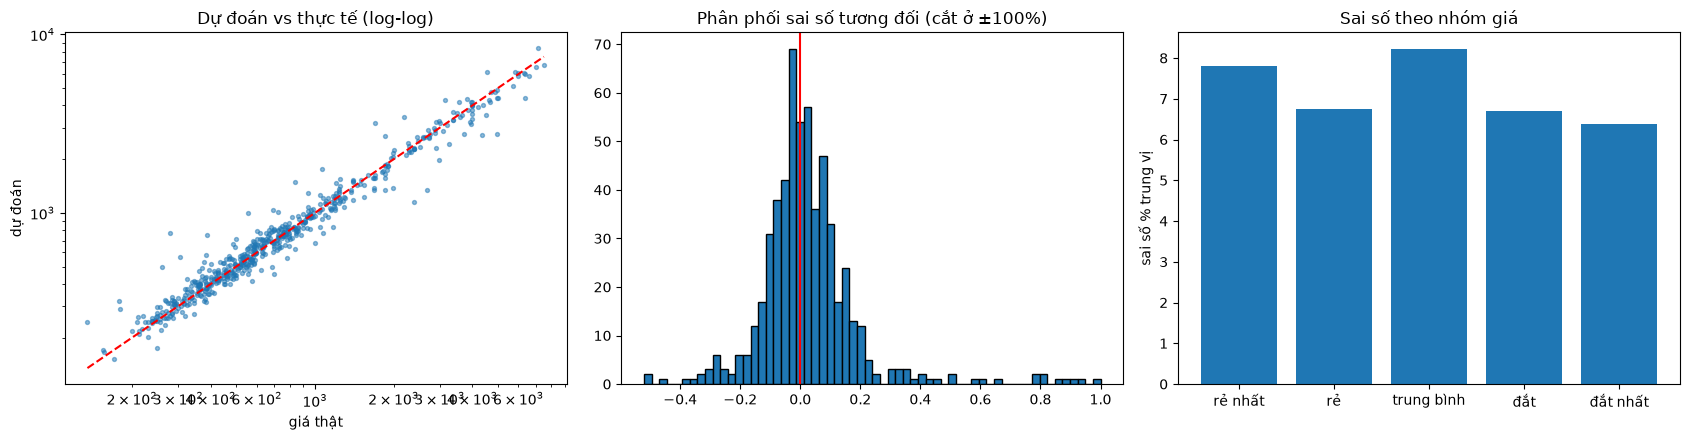

Thiên lệch trung bình (dự đoán - thật)/thật: +2.7% (dương: mô hình hay đoán cao hơn)


In [5]:
te = X_te.copy(); te["giá thật"] = y_te; te["dự đoán"] = pred
te["sai số %"] = (te["dự đoán"] - te["giá thật"]) / te["giá thật"]

fig, ax = plt.subplots(1, 3, figsize=(17, 4.5))
ax[0].scatter(te["giá thật"], te["dự đoán"], s=8, alpha=.5); lim = [te["giá thật"].min(), te["giá thật"].max()]; ax[0].plot(lim, lim, "r--")
ax[0].set_xscale("log"); ax[0].set_yscale("log"); ax[0].set_xlabel("giá thật"); ax[0].set_ylabel("dự đoán"); ax[0].set_title("Dự đoán vs thực tế (log-log)")
ax[1].hist(te["sai số %"].clip(-1, 1), bins=60, edgecolor="k"); ax[1].set_title("Phân phối sai số tương đối (cắt ở ±100%)"); ax[1].axvline(0, c="r")
te["nhóm giá"] = pd.qcut(te["giá thật"], 5, labels=["rẻ nhất", "rẻ", "trung bình", "đắt", "đắt nhất"])
g = te.groupby("nhóm giá")["sai số %"].agg(lambda s: s.abs().median()); ax[2].bar(g.index.astype(str), g.values * 100); ax[2].set_ylabel("sai số % trung vị"); ax[2].set_title("Sai số theo nhóm giá")
plt.tight_layout(); plt.show()
print("Thiên lệch trung bình (dự đoán - thật)/thật:", f"{te['sai số %'].mean():+.1%}", "(dương: mô hình hay đoán cao hơn)")

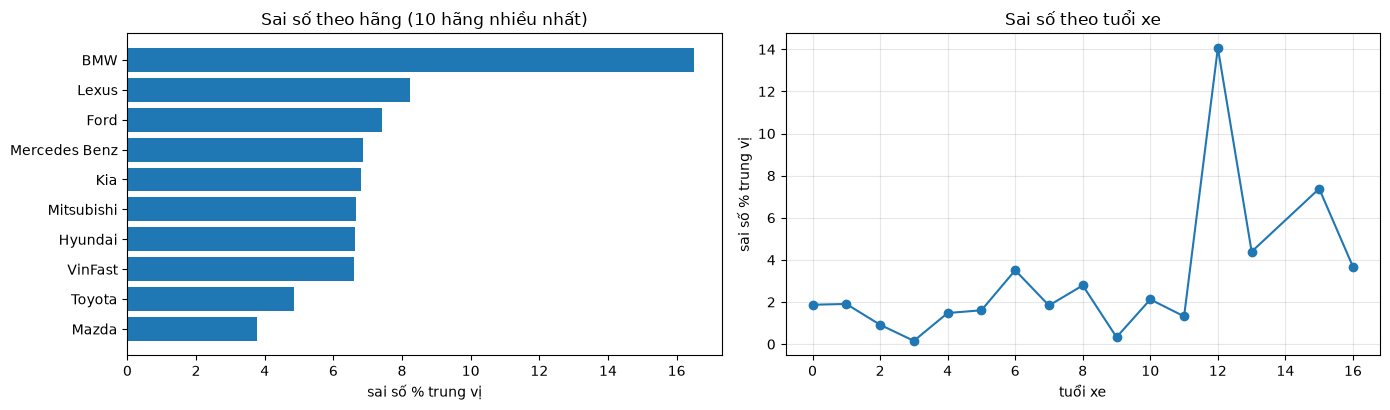

10 dự đoán sai nhiều nhất:


,brand,model,age,km,giá thật,dự đoán,sai số %
2079,Acura,MDX,18,98600.0,280.0,767.54,1.74
2655,Mercedes Benz,CLA,11,78000.0,388.0,749.38,0.93
2758,Lexus,RX,23,120000.0,260.0,495.69,0.91
152,Bentley,Flying,15,41000.0,1700.0,3185.10,0.87
2293,Toyota,Venza,17,82.0,305.0,567.39,0.86
2751,Ford,Focus,16,190000.0,135.0,245.23,0.82
73,Jaguar,XF,12,120000.0,555.0,1000.25,0.80
1001,Volkswagen,Tiguan,16,65000.0,179.0,320.06,0.79
212,Honda,Civic,1,5800.0,839.0,1486.89,0.77
2216,Audi,TT,10,25000.0,1068.0,1763.46,0.65


In [6]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4.2))
top = te["brand"].value_counts().head(10).index
g = te[te["brand"].isin(top)].groupby("brand")["sai số %"].agg(lambda s: s.abs().median()).sort_values()
ax[0].barh(g.index, g.values * 100); ax[0].set_xlabel("sai số % trung vị"); ax[0].set_title("Sai số theo hãng (10 hãng nhiều nhất)")
g2 = te.groupby("age")["sai số %"].agg(["median", "count"]); g2 = g2[g2["count"] >= 8]
ax[1].plot(g2.index, g2["median"].abs() * 100, "o-"); ax[1].set_xlabel("tuổi xe"); ax[1].set_ylabel("sai số % trung vị"); ax[1].set_title("Sai số theo tuổi xe"); ax[1].grid(alpha=.3)
plt.tight_layout(); plt.show()

print("10 dự đoán sai nhiều nhất:")
display(te.reindex(te["sai số %"].abs().sort_values(ascending=False).index).head(10)[["brand", "model", "age", "km", "giá thật", "dự đoán", "sai số %"]].round(2))

**Cách đọc:** đừng chỉ nhìn một con số tổng. Hãy tìm **nhóm** mô hình yếu (hãng hiếm, xe rất cũ, xe sang). Với các dòng sai nhiều nhất, thử trả lời: dữ liệu có lỗi (nhập nhầm giá, km vô lý) hay mô hình thiếu thông tin (đời xe, phiên bản, tình trạng, thương lượng)?

## 5. Đường cong học

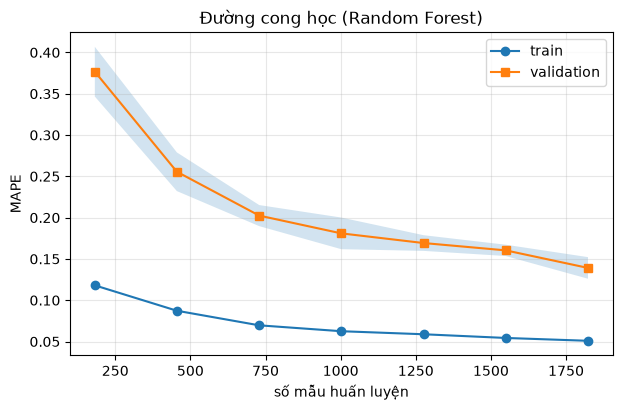

In [7]:
rf_pipe = log_target(Pipeline([("prep", build_preprocessor(False)), ("model", RandomForestRegressor(100, random_state=0, n_jobs=-1))]))
sizes, tr_s, va_s = learning_curve(rf_pipe, X_tr, y_tr, cv=5, scoring="neg_mean_absolute_percentage_error", train_sizes=np.linspace(0.1, 1, 7), shuffle=True, random_state=0)
plt.plot(sizes, -tr_s.mean(1), "o-", label="train"); plt.plot(sizes, -va_s.mean(1), "s-", label="validation")
plt.fill_between(sizes, -va_s.mean(1) - va_s.std(1), -va_s.mean(1) + va_s.std(1), alpha=.2)
plt.xlabel("số mẫu huấn luyện"); plt.ylabel("MAPE"); plt.legend(); plt.grid(alpha=.3); plt.title("Đường cong học (Random Forest)"); plt.show()

**Chẩn đoán:**
- Đường validation vẫn **đang giảm** khi thêm dữ liệu → thu thập thêm dữ liệu sẽ giúp.
- Hai đường đã sát nhau mà sai số vẫn cao → mô hình/đặc trưng chưa đủ (bias cao): cần đặc trưng tốt hơn.
- Khoảng cách lớn giữa train và validation → phương sai cao: thêm dữ liệu hoặc đơn giản hoá mô hình.

## 6. Khoảng dự đoán bằng quantile regression

Một con số đơn lẻ dễ gây hiểu lầm. Ta huấn luyện thêm hai mô hình dự đoán **phân vị 10% và 90%** của giá, để đưa ra khoảng "80% khả năng giá nằm trong đây".

Tỉ lệ giá thật nằm trong khoảng [P10, P90]: 77.4%  (kỳ vọng ~80%)
Độ rộng khoảng tương đối trung vị: 95.6%


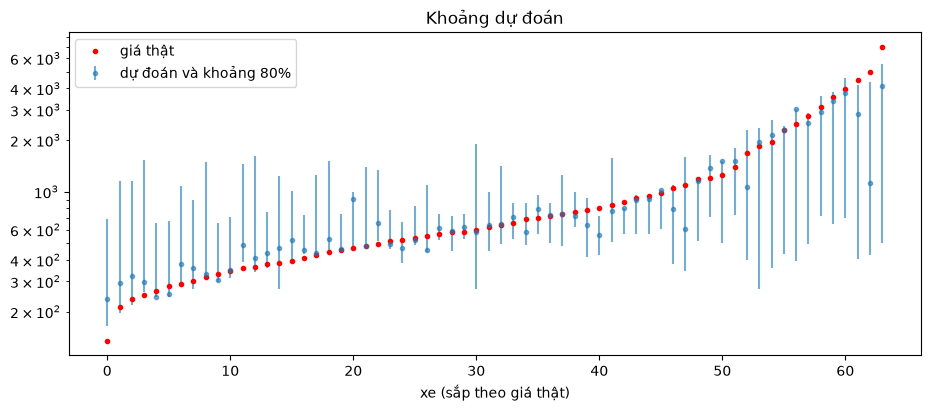

In [8]:
prep = build_preprocessor(False).fit(X_tr); A_tr, A_te = prep.transform(X_tr).toarray(), prep.transform(X_te).toarray()
ly = np.log1p(y_tr)
qs = {}
for a in [0.1, 0.5, 0.9]:
    qs[a] = GradientBoostingRegressor(loss="quantile", alpha=a, n_estimators=400, learning_rate=0.05, max_depth=4, subsample=0.8, random_state=0).fit(A_tr, ly)
lo, mid, hi = (np.expm1(qs[a].predict(A_te)) for a in [0.1, 0.5, 0.9])
hi = np.maximum(hi, mid); lo = np.minimum(lo, mid)
cover = np.mean((y_te.values >= lo) & (y_te.values <= hi))
print(f"Tỉ lệ giá thật nằm trong khoảng [P10, P90]: {cover:.1%}  (kỳ vọng ~80%)")
print(f"Độ rộng khoảng tương đối trung vị: {np.median((hi - lo) / mid):.1%}")

idx = np.argsort(y_te.values)[::max(1, len(y_te) // 60)]
plt.figure(figsize=(11, 4.2))
plt.errorbar(range(len(idx)), mid[idx], yerr=[mid[idx] - lo[idx], hi[idx] - mid[idx]], fmt="o", ms=3, alpha=.6, label="dự đoán và khoảng 80%")
plt.plot(range(len(idx)), y_te.values[idx], "r.", label="giá thật"); plt.yscale("log"); plt.xlabel("xe (sắp theo giá thật)"); plt.legend(); plt.title("Khoảng dự đoán"); plt.show()

Nếu độ phủ thấp hơn nhiều so với 80% thì khoảng bị **quá tự tin**; nếu cao hơn nhiều thì khoảng **quá rộng**. Kiểm tra độ phủ (calibration) là bước thường bị bỏ quên.

## 7. Lưu mô hình và những cạm bẫy thường gặp

In [9]:
tmp = ROOT / "models" / "tuned_gb_example.joblib"
joblib.dump(best, tmp); reloaded = joblib.load(tmp)
print("Mô hình tải lại cho cùng kết quả:", np.allclose(reloaded.predict(X_te), pred))
tmp.unlink()    # xoá file ví dụ

Mô hình tải lại cho cùng kết quả: True


**Cạm bẫy cần tránh:**
1. **Rò rỉ dữ liệu (data leakage):** mọi bước học từ dữ liệu (chuẩn hoá, one-hot, chọn đặc trưng, tinh chỉnh) phải nằm trong `Pipeline` và chỉ `fit` trên train. Ở đây ta đã làm vậy.
2. **Nhìn trộm tập test:** nếu bạn tinh chỉnh dựa trên điểm test, điểm đó không còn là ước lượng trung thực.
3. **Tin rao trùng nhau:** cùng một xe đăng nhiều lần có thể rơi vào cả train và test, làm điểm cao giả. (Đã bỏ trùng theo `listing_id`; nhưng cùng xe đăng lại với mã tin khác vẫn có thể còn.)
4. **Dữ liệu thay đổi theo thời gian:** thị trường biến động; mô hình huấn luyện hôm nay sẽ lệch dần. Cần đánh giá lại định kỳ.
5. **Giá chào bán ≠ giá giao dịch.**

## Bài tập
1. Chạy `RandomizedSearchCV` với `n_iter=40`. Kết quả tốt hơn bao nhiêu? Có đáng với thời gian chạy không?
2. Thay vì chia ngẫu nhiên, hãy chia theo `listing_id` (tin mới làm test). MAPE thay đổi thế nào? Vì sao?
3. Tính độ phủ của khoảng [P5, P95]. Có gần 90% không?
4. Chọn một nhóm mô hình yếu từ phần 4 và đề xuất một đặc trưng mới có thể giúp (vd. số km mỗi năm, hãng thuộc nhóm sang).
5. Dùng `GroupKFold` theo `model` để kiểm tra mô hình khái quát hoá cho **dòng xe chưa từng thấy** tốt tới đâu.